# Exploratory analysis

A workspace for developing Matthew's day-local features. The first question: **do estrus days spend more of hours 6–12 above a CBT or locomotor activity (LA) threshold? Which thresholds separate the days consistently across mice?**

For signal $x$, define

$$p_x(t)=\frac{\#\{\text{observed readings in }[6,12)\text{ with }x>t\}}{\#\{\text{observed readings in }[6,12)\}}.$$

A threshold of 38 °C with 270 of 360 readings above it gives a CBT feature of 0.75. **The sensor threshold $t$ is different from a classifier's decision cutoff.** We tune the sensor threshold here and keep the fraction as a continuous feature; we do not pick a fraction cutoff to call a day estrus.

The files have no clock timestamps: “6–12” means **elapsed hours within each 24-hour recording segment**, minutes 360–719. Confirm the alignment before interpreting this as 6 a.m.–noon. Current labels mark recording days 2, 6, and 10 as estrus using an **unverified paper-alignment proxy**, not independent biological staging. Temperature-based proxy labels can favor temperature features.

Run all cells using the project `.venv` kernel. Change the controls below to explore a new question. This notebook reads the original inputs, writes no feature export, and leaves the shared model unchanged.

In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import average_precision_score
from sklearn.model_selection import LeaveOneGroupOut

# Works from this folder or the repository root, even without an editable install.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data/inputs/fem_temp.csv").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside capstone-estrus-classification.")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from estrus.data import KEYS, canonical_keys, iter_days, load_labels
from estrus.modeling import split_mice

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.2})
COLORS = {0: "#3876a8", 1: "#d45a38"}
CLASS_NAMES = {0: "Non-estrus (proxy)", 1: "Estrus (proxy)"}
SIGNAL_NAMES = {"cbt": "CBT (°C)", "la": "LA (counts/minute)"}

## Controls

Use a fixed grid in measurement units so the candidates do not depend on a validation mouse's measurements. CBT uses 0.1 °C steps; LA uses 5 counts/minute steps. Inspect the whole curve before refining the grid. A broad high-scoring region is more reassuring than a single sharp maximum.

Coverage is checked separately for each signal. Missing readings are excluded from the denominator; a window with less than 80% coverage gets NaN. No smoothing, interpolation, or outlier clipping is applied. A valid reading equal to the threshold is **not** above it.

In [2]:
START_HOUR, END_HOUR = 6, 12   # [start, end), elapsed recording-day hours
MIN_COVERAGE = 0.80
LABEL_PATH = None             # None = project proxy; or Path to a curated label CSV
THRESHOLDS = {
    "cbt": np.round(np.arange(35.0, 40.01, 0.1), 2),
    "la": np.arange(0.0, 150.01, 5.0),
}

assert 0 <= START_HOUR < END_HOUR <= 24
assert 0 < MIN_COVERAGE <= 1
START_MINUTE, END_MINUTE = int(START_HOUR * 60), int(END_HOUR * 60)
WINDOW_MINUTES = END_MINUTE - START_MINUTE
MIN_OBSERVED = int(np.ceil(MIN_COVERAGE * WINDOW_MINUTES))
WINDOW_LABEL = f"hours {START_HOUR:g}–{END_HOUR:g}"
CONFIG = json.loads((ROOT / "Model Building/config.json").read_text())

## Load aligned days and reserve the project's test mice

Days 1 and 14 are excluded by the shared loader. Labels are joined by mouse and recording day. Unknown targets stay out of supervised exploration. The split uses the same function, configuration, and mouse-day order as model building. All subsequent plots and tuning use **development mice only**.

In [3]:
days = {(mouse, day_index): day for mouse, day_index, day in iter_days(ROOT)}
cohort = canonical_keys().merge(load_labels(LABEL_PATH), on=KEYS,
                               how="left", validate="one_to_one")
cohort = cohort.dropna(subset=["is_estrus"]).reset_index(drop=True)
cohort["is_estrus"] = cohort.is_estrus.astype(int)
train_idx, test_idx = split_mice(cohort.is_estrus.to_numpy(),
                                 cohort.mouse_id.to_numpy(), CONFIG)
dev = cohort.iloc[train_idx].reset_index(drop=True)
reserved_mice = sorted(cohort.iloc[test_idx].mouse_id.unique())
assert not set(dev.mouse_id) & set(reserved_mice)
print(f"Development: {len(dev)} days from {dev.mouse_id.nunique()} mice")
print(f"Reserved test mice (excluded below): {', '.join(reserved_mice)}")
print("Label source(s):", ", ".join(sorted(dev.label_source.unique())))
display(pd.crosstab(dev.mouse_id, dev.is_estrus)
        .rename(columns=CLASS_NAMES).rename_axis(columns=None))

# Arrays preserve exactly the order of dev. Each row is one mouse-day.
full_day = {s: np.stack([days[(r.mouse_id, r.day_index)][s].to_numpy()
                        for r in dev.itertuples()]) for s in SIGNAL_NAMES}
window = {s: x[:, START_MINUTE:END_MINUTE] for s, x in full_day.items()}
coverage = pd.DataFrame({s: np.isfinite(x).mean(axis=1) for s, x in window.items()})
display(pd.DataFrame({
    "minimum_window_coverage": coverage.min(),
    "days_below_required_coverage": (coverage < MIN_COVERAGE).sum(),
    "window_minutes": WINDOW_MINUTES,
    "minimum_observed_minutes": MIN_OBSERVED,
}))

Development: 120 days from 10 mice
Reserved test mice (excluded below): f11, f3, f6
Label source(s): paper_alignment_proxy_days_2_6_10_UNVERIFIED


,Non-estrus (proxy),Estrus (proxy)
mouse_id,,
f1,9,3
f10,9,3
f12,9,3
f13,9,3
f2,9,3
f4,9,3
f5,9,3
f7,9,3
f8,9,3


,minimum_window_coverage,days_below_required_coverage,window_minutes,minimum_observed_minutes
cbt,1.0,0,360,288
la,1.0,0,360,288


## Check the proposed time window

Each thin line is one mouse's class-average trajectory; thick lines average those mouse means. A 15-minute rolling mean is used **only for display**. The shaded region is the proposed window. This shows whether the effect is shared across animals or driven by a few mice.

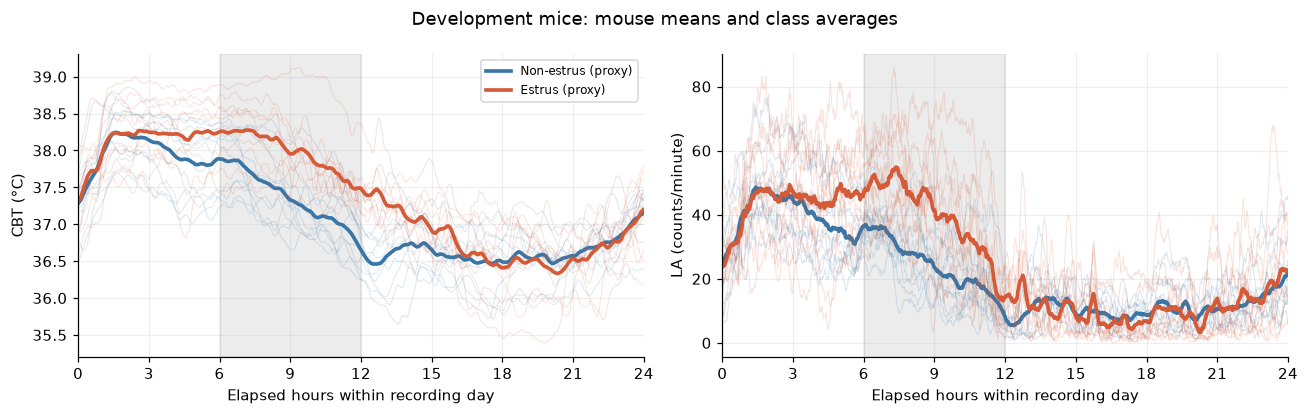

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharex=True)
for ax, signal in zip(axes, SIGNAL_NAMES):
    for label, color in COLORS.items():
        curves = []
        for mouse in dev.mouse_id.unique():
            selected = (dev.mouse_id.eq(mouse) & dev.is_estrus.eq(label)).to_numpy()
            if not selected.any():
                continue
            curve = pd.DataFrame(full_day[signal][selected]).mean(axis=0)
            curve = curve.rolling(15, center=True, min_periods=1).mean().to_numpy()
            curves.append(curve)
            ax.plot(np.arange(1440) / 60, curve, color=color, alpha=.16, lw=.7)
        ax.plot(np.arange(1440) / 60, pd.DataFrame(curves).mean(axis=0),
                color=color, lw=2.4, label=CLASS_NAMES[label])
    ax.axvspan(START_HOUR, END_HOUR, color="grey", alpha=.15)
    ax.set(xlabel="Elapsed hours within recording day", ylabel=SIGNAL_NAMES[signal],
           xlim=(0, 24), xticks=np.arange(0, 25, 3))
axes[0].legend(fontsize=8)
fig.suptitle("Development mice: mouse means and class averages")
plt.tight_layout()
plt.show()

## Build the threshold features

Each mouse-day contributes one fraction, so 360 correlated minutes are not treated as 360 independent examples. CBT and LA thresholds are tuned separately. The two additional features give useful comparisons: the window's ordinary mean, and the fraction above **that same day's full-day 75th percentile**. The latter asks whether this window is unusually high relative to the day's own signal, reducing sensitivity to absolute offsets without using another day or mouse.

In [5]:
def fraction_above(values, thresholds):
    """Rows = days; columns = thresholds. Invalid windows remain NaN."""
    values = np.asarray(values, dtype=float)
    thresholds = np.asarray(thresholds, dtype=float)
    observed = np.isfinite(values)
    counts = observed.sum(axis=1)
    above = ((values[:, :, None] > thresholds[None, None, :])
             & observed[:, :, None]).sum(axis=1)
    result = above / np.maximum(counts[:, None], 1)
    result[counts < MIN_OBSERVED] = np.nan
    return result

features = {}
comparators = {}
for signal in SIGNAL_NAMES:
    grid = np.asarray(THRESHOLDS[signal], dtype=float)
    assert len(grid) > 1 and np.isfinite(grid).all() and (np.diff(grid) > 0).all()
    features[signal] = pd.DataFrame(fraction_above(window[signal], grid), columns=grid)
    valid = coverage[signal].ge(MIN_COVERAGE).to_numpy()
    window_mean = pd.DataFrame(window[signal]).mean(axis=1).to_numpy()
    day_q75 = pd.DataFrame(full_day[signal]).quantile(.75, axis=1).to_numpy()
    counts = np.isfinite(window[signal]).sum(axis=1)
    relative = ((window[signal] > day_q75[:, None])
                & np.isfinite(window[signal])).sum(axis=1) / np.maximum(counts, 1)
    # Also require enough full-day data to estimate the reference quantile.
    relative_valid = valid & (np.isfinite(full_day[signal]).mean(axis=1) >= MIN_COVERAGE)
    comparators[signal] = pd.DataFrame({
        "window_mean": np.where(valid, window_mean, np.nan),
        "fraction_above_own_day_q75": np.where(relative_valid, relative, np.nan),
    })
    assert features[signal].shape == (len(dev), len(grid))
    assert np.nanmin(features[signal].to_numpy()) >= 0
    assert np.nanmax(features[signal].to_numpy()) <= 1
    assert np.all(np.diff(features[signal].to_numpy(), axis=1)[valid] <= 1e-12)

# Boundary / missingness checks for the feature definition.
probe = np.full((2, WINDOW_MINUTES), np.nan)
probe[0, :MIN_OBSERVED] = 2.0
probe[1, :MIN_OBSERVED - 1] = 2.0
probe_features = fraction_above(probe, np.array([1.0, 2.0]))
assert np.array_equal(probe_features[0], [1.0, 0.0])  # Strict >, correct denominator.
assert np.isnan(probe_features[1]).all()             # Insufficient coverage.

## Sweep thresholds and examine stability across mice

Use the fraction itself as an estrus-ranking score: the hypothesis is **higher fraction → more likely estrus**. Average precision (AP) measures that ranking; it does not require a classifier or a fraction decision cutoff. AP = 1 is perfect, and a constant score gives that mouse's positive fraction (currently 0.25).

For each candidate, leave one development mouse out at a time. Missing features are filled using only the remaining mice's median (zero if all fitting values are missing). Average AP **equally across mice**. The class gap is mean estrus fraction minus mean non-estrus fraction, also averaged equally across mice. A negative gap challenges the proposed direction.

The highest curve point is a **selection score**, which is optimistic because we searched thresholds. The nested check below evaluates the selection procedure on mice omitted from the search. The shaded band is between-mouse standard deviation, not a confidence interval.

CBT (°C): selected threshold = 37.2
LA (counts/minute): selected threshold = 15


,mean_mouse_ap,sd_mouse_ap,worst_mouse_ap,mean_gap,baseline_ap
sensor_threshold,,,,,
37.2,0.967,0.058,0.833,0.353,0.25
37.1,0.958,0.081,0.750,0.346,0.25
37.0,0.950,0.158,0.500,0.323,0.25
37.3,0.946,0.074,0.810,0.357,0.25
36.9,0.935,0.180,0.429,0.296,0.25
37.4,0.932,0.093,0.756,0.347,0.25
37.5,0.927,0.111,0.667,0.336,0.25
36.8,0.917,0.201,0.375,0.260,0.25


,mean_mouse_ap,sd_mouse_ap,worst_mouse_ap,mean_gap,baseline_ap
sensor_threshold,,,,,
15.0,0.928,0.132,0.578,0.209,0.25
0.0,0.927,0.123,0.625,0.171,0.25
5.0,0.924,0.135,0.578,0.187,0.25
20.0,0.924,0.129,0.578,0.217,0.25
30.0,0.918,0.134,0.592,0.218,0.25
40.0,0.918,0.135,0.587,0.208,0.25
25.0,0.914,0.144,0.556,0.218,0.25
10.0,0.914,0.134,0.578,0.199,0.25


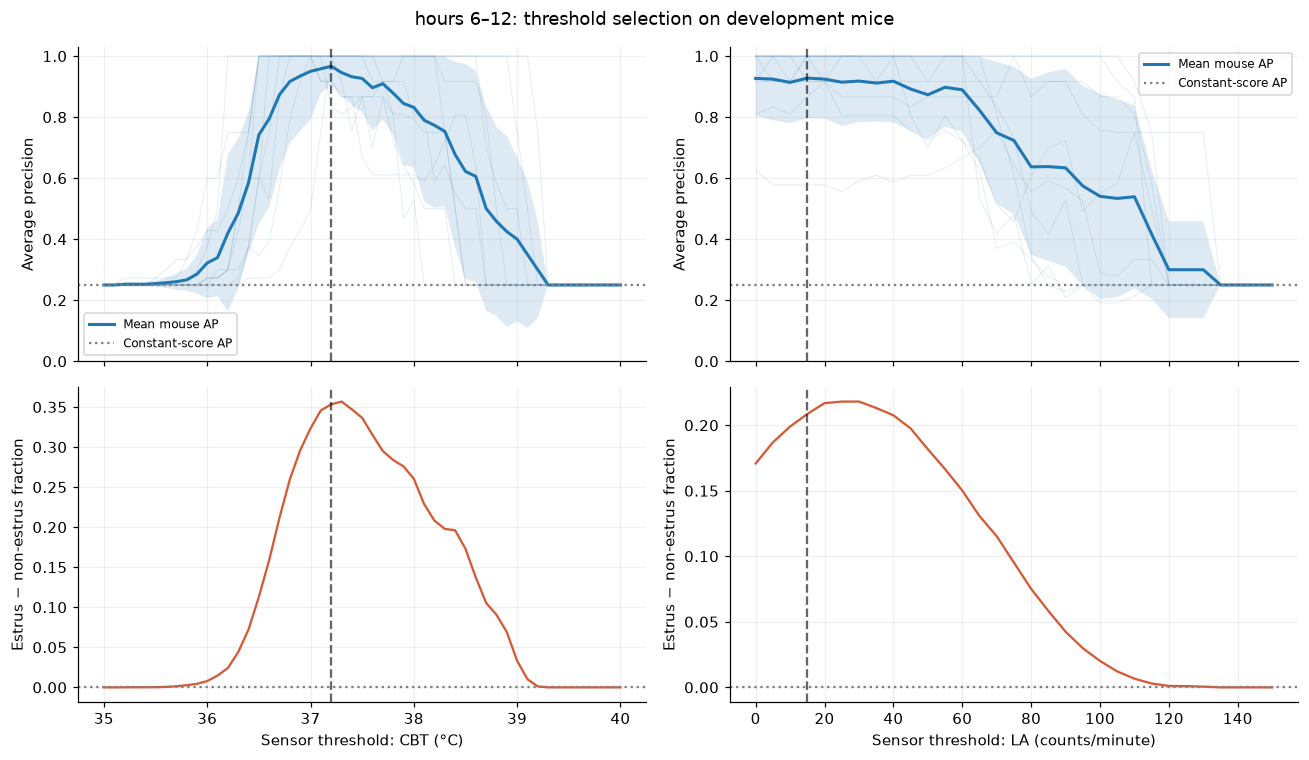

In [6]:
def impute_from_fit(fit, validation):
    """Never estimate a missing-value replacement from the validation mouse."""
    fit = np.asarray(fit, dtype=float)
    observed = fit[np.isfinite(fit)]
    median = float(np.median(observed)) if len(observed) else 0.0
    return np.where(np.isfinite(validation), validation, median)


def score_candidates(frame, metadata):
    y = metadata.is_estrus.to_numpy()
    groups = metadata.mouse_id.to_numpy()
    rows = []
    for fit, val in LeaveOneGroupOut().split(frame, y, groups):
        if len(np.unique(y[fit])) != 2 or len(np.unique(y[val])) != 2:
            raise ValueError("Each fitting/validation set needs both classes; review curated labels.")
        for candidate in frame.columns:
            raw = frame[candidate].to_numpy()
            score = impute_from_fit(raw[fit], raw[val])
            rows.append({
                "candidate": candidate, "mouse_id": groups[val][0],
                "ap": average_precision_score(y[val], score),
                "prevalence": y[val].mean(),
                "estrus_minus_non": score[y[val] == 1].mean() - score[y[val] == 0].mean(),
            })
    folds = pd.DataFrame(rows)
    summary = folds.groupby("candidate", sort=False).agg(
        mean_mouse_ap=("ap", "mean"), sd_mouse_ap=("ap", "std"),
        worst_mouse_ap=("ap", "min"), mean_gap=("estrus_minus_non", "mean"),
        baseline_ap=("prevalence", "mean"),
    )
    return summary, folds


def choose_threshold(summary):
    # Deterministic tie-break: use the middle grid point among equal maxima.
    tied = summary.index[np.isclose(summary.mean_mouse_ap, summary.mean_mouse_ap.max(),
                                   rtol=0, atol=1e-12)]
    return float(tied[len(tied) // 2])

sweeps, sweep_folds, selected_thresholds = {}, {}, {}
for signal in SIGNAL_NAMES:
    sweeps[signal], sweep_folds[signal] = score_candidates(features[signal], dev)
    selected_thresholds[signal] = choose_threshold(sweeps[signal])
    print(f"{SIGNAL_NAMES[signal]}: selected threshold = {selected_thresholds[signal]:g}")
    display(sweeps[signal].sort_values("mean_mouse_ap", ascending=False, kind="stable")
            .head(8).rename_axis("sensor_threshold").round(3))

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex="col")
for column, signal in enumerate(SIGNAL_NAMES):
    summary = sweeps[signal]
    x = summary.index.to_numpy(dtype=float)
    mean, sd = summary.mean_mouse_ap.to_numpy(), summary.sd_mouse_ap.to_numpy()
    for mouse, block in sweep_folds[signal].groupby("mouse_id", sort=False):
        axes[0, column].plot(block.candidate, block.ap, color="#3876a8", alpha=.12, lw=.7)
    axes[0, column].fill_between(x, np.maximum(0, mean - sd),
                                 np.minimum(1, mean + sd), alpha=.15)
    axes[0, column].plot(x, mean, lw=2, label="Mean mouse AP")
    axes[0, column].axhline(summary.baseline_ap.mean(), color="grey", ls=":", label="Constant-score AP")
    axes[0, column].set(ylabel="Average precision", ylim=(0, 1.03))
    axes[0, column].legend(fontsize=8)
    axes[1, column].plot(x, summary.mean_gap, color="#d45a38")
    axes[1, column].axhline(0, color="grey", ls=":")
    axes[1, column].set(xlabel=f"Sensor threshold: {SIGNAL_NAMES[signal]}",
                         ylabel="Estrus − non-estrus fraction")
    for row in range(2):
        axes[row, column].axvline(selected_thresholds[signal], color="black", ls="--", alpha=.6)
fig.suptitle(f"{WINDOW_LABEL}: threshold selection on development mice")
plt.tight_layout()
plt.show()

## Inspect individual days at a threshold

Change `EXPLORE_THRESHOLDS` and rerun the next cell. The left panels show the full threshold-response curves (one line per day), with the fraction computed within each day before averaging. The right panels show the day fractions at the chosen threshold, separated by mouse and class. Overlap reveals exceptions that a class-average plot can hide. These are descriptive plots of development data, including the mice used to select the thresholds.

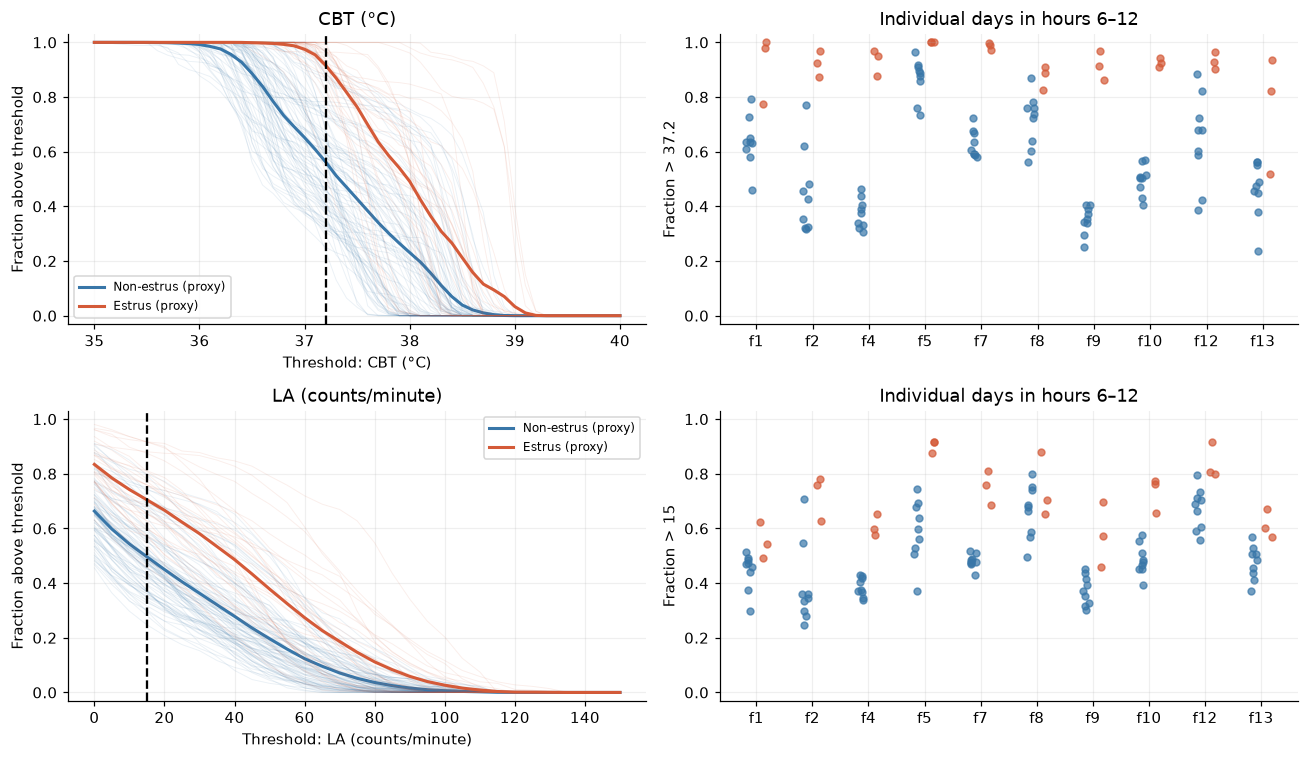

In [7]:
EXPLORE_THRESHOLDS = dict(selected_thresholds)
# Examples to try instead: EXPLORE_THRESHOLDS = {"cbt": 38.0, "la": 50.0}


def inspect_thresholds(thresholds):
    rng = np.random.default_rng(190)  # Reproducible display jitter only.
    fig, axes = plt.subplots(2, 2, figsize=(12, 7))
    mice = list(dev.mouse_id.unique())
    for row, signal in enumerate(SIGNAL_NAMES):
        t = thresholds[signal]
        values = fraction_above(window[signal], np.array([t]))[:, 0]
        for label, color in COLORS.items():
            mask = dev.is_estrus.eq(label).to_numpy()
            axes[row, 0].plot(features[signal].columns, features[signal].to_numpy()[mask].T,
                              color=color, alpha=.10, lw=.6)
            axes[row, 0].plot(features[signal].columns, features[signal].loc[mask].mean(),
                              color=color, lw=2, label=CLASS_NAMES[label])
            for i, mouse in enumerate(mice):
                chosen = mask & dev.mouse_id.eq(mouse).to_numpy()
                offset = -.13 if label == 0 else .13
                axes[row, 1].scatter(i + offset + rng.uniform(-.06, .06, chosen.sum()),
                                     values[chosen], color=color, s=20, alpha=.7)
        axes[row, 0].axvline(t, color="black", ls="--")
        axes[row, 0].set(xlabel=f"Threshold: {SIGNAL_NAMES[signal]}", ylabel="Fraction above threshold",
                         ylim=(-.03, 1.03), title=SIGNAL_NAMES[signal])
        axes[row, 0].legend(fontsize=8)
        axes[row, 1].set(xticks=range(len(mice)), xticklabels=mice,
                         ylabel=f"Fraction > {t:g}", ylim=(-.03, 1.03),
                         title=f"Individual days in {WINDOW_LABEL}")
    plt.tight_layout()
    plt.show()

inspect_thresholds(EXPLORE_THRESHOLDS)

## Does threshold tuning generalize to another development mouse?

**Nested leave-one-mouse-out check:** set one development mouse aside; choose the threshold using mean leave-one-mouse-out AP on the other mice; then score the set-aside mouse using that threshold. Repeat for every development mouse. This separates threshold selection from its evaluation. Missing-value replacements are recomputed from fitting mice at every level.

Compare against the window mean and the within-day 75th-percentile fraction on the same held-out mice. A tuned fraction should add value beyond simply taking the mean. Variable selected thresholds suggest that a single absolute cutoff may not transfer well.

This assesses the two fixed threshold-search procedures separately. Choosing a signal, window, coverage rule, or grid after viewing these results is still exploratory model selection. The standard deviations below describe mouse-to-mouse variability; they are not confidence intervals. The reserved project test mice remain unused.

mean_mouse_ap  ...  baseline_ap
signal method                                     ...             
cbt    fraction_above_own_day_q75          0.775  ...         0.25
       tuned_absolute_fraction             0.917  ...         0.25
       window_mean                         0.953  ...         0.25
la     fraction_above_own_day_q75          0.899  ...         0.25
       tuned_absolute_fraction             0.894  ...         0.25
       window_mean                         0.914  ...         0.25

[6 rows x 4 columns]

,signal,held_out_mouse,selected_threshold,held_out_mouse_ap
0,cbt,f1,37.2,0.917
1,cbt,f10,37.2,1.000
2,cbt,f12,37.2,1.000
3,cbt,f13,37.2,0.833
4,cbt,f2,37.2,1.000
5,cbt,f4,37.2,1.000
6,cbt,f5,37.0,0.500
7,cbt,f7,37.2,1.000
8,cbt,f8,37.2,0.917
9,cbt,f9,37.2,1.000


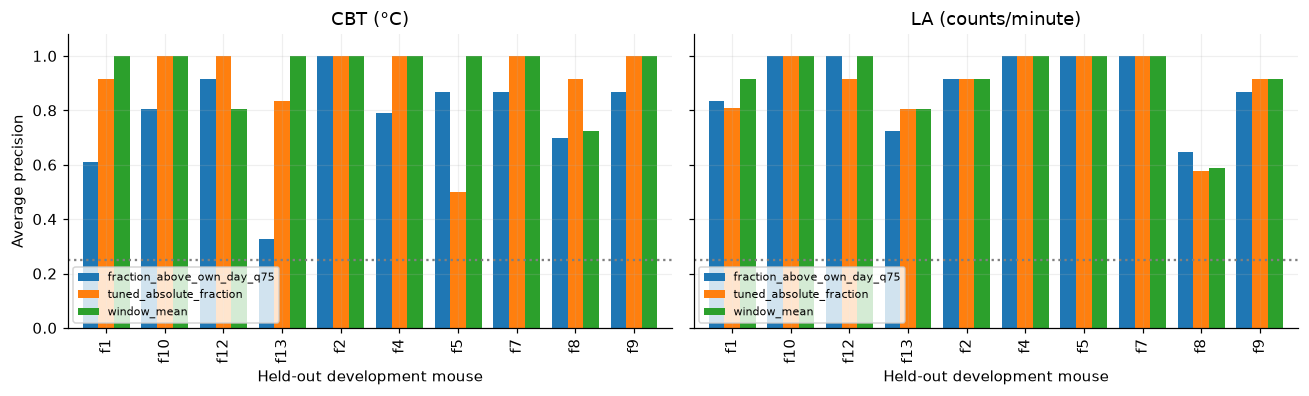

In [8]:
nested_rows = []
y = dev.is_estrus.to_numpy()
groups = dev.mouse_id.to_numpy()
for signal in SIGNAL_NAMES:
    for fit, val in LeaveOneGroupOut().split(dev, y, groups):
        fitting_metadata = dev.iloc[fit].reset_index(drop=True)
        inner_summary, _ = score_candidates(features[signal].iloc[fit].reset_index(drop=True),
                                             fitting_metadata)
        threshold = choose_threshold(inner_summary)
        candidates = {"tuned_absolute_fraction": features[signal][threshold].to_numpy()}
        candidates.update({name: comparators[signal][name].to_numpy()
                           for name in comparators[signal]})
        for method, raw in candidates.items():
            score = impute_from_fit(raw[fit], raw[val])
            nested_rows.append({
                "signal": signal, "method": method, "held_out_mouse": groups[val][0],
                "selected_threshold": threshold if method == "tuned_absolute_fraction" else np.nan,
                "held_out_mouse_ap": average_precision_score(y[val], score),
                "constant_score_ap": y[val].mean(),
            })
nested = pd.DataFrame(nested_rows)
comparison = nested.groupby(["signal", "method"]).agg(
    mean_mouse_ap=("held_out_mouse_ap", "mean"),
    sd_mouse_ap=("held_out_mouse_ap", "std"),
    worst_mouse_ap=("held_out_mouse_ap", "min"),
    baseline_ap=("constant_score_ap", "mean"),
)
display(comparison.round(3))
display(nested.query("method == 'tuned_absolute_fraction'")
        [["signal", "held_out_mouse", "selected_threshold", "held_out_mouse_ap"]]
        .reset_index(drop=True).round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.7), sharey=True)
for ax, signal in zip(axes, SIGNAL_NAMES):
    scores = nested[nested.signal.eq(signal)].pivot(
        index="held_out_mouse", columns="method", values="held_out_mouse_ap")
    scores.plot.bar(ax=ax, width=.8)
    ax.axhline(dev.groupby("mouse_id").is_estrus.mean().mean(), color="grey", ls=":")
    ax.set(title=SIGNAL_NAMES[signal], xlabel="Held-out development mouse",
           ylabel="Average precision", ylim=(0, 1.08))
    ax.legend(fontsize=7, loc="lower left")
plt.tight_layout()
plt.show()

## Readout and next steps

The table below separates the score used to choose each final exploratory threshold from the nested score of the tuning procedure. Do not treat the larger selection score as an independent performance estimate.

A useful candidate has positive class separation, good AP across several mice, and a reasonably broad threshold plateau. If the relative feature does better, a day-local reference may handle offsets more reliably than an absolute threshold. If the window mean does just as well, the fraction may add little on its own. Joint usefulness alongside other features still needs a model comparison.

In [9]:
readout = []
for signal in SIGNAL_NAMES:
    threshold = selected_thresholds[signal]
    chosen = sweeps[signal].loc[threshold]
    evaluated = comparison.loc[(signal, "tuned_absolute_fraction")]
    near_best = sweeps[signal].index[
        sweeps[signal].mean_mouse_ap >= sweeps[signal].mean_mouse_ap.max() - .02]
    readout.append({
        "signal": signal,
        "exploratory_threshold": threshold,
        "selection_mean_mouse_AP": chosen.mean_mouse_ap,
        "nested_tuning_mean_mouse_AP": evaluated.mean_mouse_ap,
        "nested_tuning_SD": evaluated.sd_mouse_ap,
        "mean_estrus_minus_non_fraction": chosen.mean_gap,
        "near_best_grid_points_within_0.02_AP": len(near_best),
        "near_best_min": float(min(near_best)),
        "near_best_max": float(max(near_best)),
        "selected_at_grid_edge": threshold in (THRESHOLDS[signal][0], THRESHOLDS[signal][-1]),
    })
readout = pd.DataFrame(readout).set_index("signal")
display(readout.round(3))
print("Near-best min/max is a span of grid points, not a confidence interval; inspect for disjoint peaks.")
print("No reserved test mice were plotted or scored, and no feature CSV was exported.")

observations = []
for signal in SIGNAL_NAMES:
    tuned = comparison.loc[(signal, "tuned_absolute_fraction"), "mean_mouse_ap"]
    mean = comparison.loc[(signal, "window_mean"), "mean_mouse_ap"]
    relative = comparison.loc[(signal, "fraction_above_own_day_q75"), "mean_mouse_ap"]
    delta = tuned - mean
    observations.append(
        f"- **{SIGNAL_NAMES[signal]}:** exploratory sensor threshold "
        f"**{selected_thresholds[signal]:g}**; nested mean mouse AP **{tuned:.3f}** "
        f"versus **{mean:.3f}** for the window mean and **{relative:.3f}** for the "
        f"within-day reference. Tuned fraction minus mean AP = **{delta:+.3f}**."
    )
la_zero = sweeps["la"].loc[0.0, "mean_mouse_ap"] if 0.0 in sweeps["la"].index else None
if la_zero is not None and la_zero >= sweeps["la"].mean_mouse_ap.max() - .02:
    observations.append(
        "- LA > 0 is within 0.02 AP of the best LA selection score. "
        "Compare the simple active-minute fraction before fine-tuning activity amplitude cutoffs."
    )
display(Markdown("**Observations for the current settings**\n\n" + "\n".join(observations)))


Near-best min/max is a span of grid points, not a confidence interval; inspect for disjoint peaks.
No reserved test mice were plotted or scored, and no feature CSV was exported.


,exploratory_threshold,selection_mean_mouse_AP,nested_tuning_mean_mouse_AP,nested_tuning_SD,mean_estrus_minus_non_fraction,near_best_grid_points_within_0.02_AP,near_best_min,near_best_max,selected_at_grid_edge
signal,,,,,,,,,
cbt,37.2,0.967,0.917,0.157,0.353,3,37.0,37.2,False
la,15.0,0.928,0.894,0.134,0.209,9,0.0,40.0,False


**Observations for the current settings**

- **CBT (°C):** exploratory sensor threshold **37.2**; nested mean mouse AP **0.917** versus **0.953** for the window mean and **0.775** for the within-day reference. Tuned fraction minus mean AP = **-0.036**.
- **LA (counts/minute):** exploratory sensor threshold **15**; nested mean mouse AP **0.894** versus **0.914** for the window mean and **0.899** for the within-day reference. Tuned fraction minus mean AP = **-0.020**.
- LA > 0 is within 0.02 AP of the best LA selection score. Compare the simple active-minute fraction before fine-tuning activity amplitude cutoffs.

**How to continue**

- Refine the threshold grid around a stable region, then rerun all cells. If the best point is at a grid edge, inspect whether the search range needs extending.
- Once the time alignment is confirmed, explore alternate windows by changing the controls. Keep a record of each hypothesis; repeated window searches also tune the analysis.
- Look at mice with low AP and overlap in the day plots. Decide whether a day-local reference helps before adding more thresholds.
- For a model comparison, evaluate CBT alone, LA alone, and both together against simple window means within grouped training folds. These two fractions may carry overlapping information.
- **Production handoff:** the feature contract requires population-learned thresholds to be selected inside training folds. Do not copy a label-tuned threshold from this notebook into `features.py` and describe downstream validation as independent. Integrate a fitted threshold transformer into the training pipeline, or export a predeclared fixed bank of threshold fractions and let the pipeline select columns inside its folds; even a bank should be assessed on mice excluded from its design.
- Confirm the proxy labels or replace `LABEL_PATH` with an independently curated CSV before making biological claims.

### Exploration log

| Question / settings | Observation | Follow-up |
| --- | --- | --- |
| CBT / LA fraction above a threshold in elapsed hours 6–12 | See the development sweep and nested check above | Confirm alignment and labels; compare with window means |

### Next analysis

Add further feature ideas and their evidence below.